In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# OPTION 1: Upload CSV manually in Colab
from google.colab import files
uploaded = files.upload()

Saving Student Evaluation Final.xlsx to Student Evaluation Final.xlsx


In [5]:
# OPTION 2: If Excel file
df = pd.read_excel('/content/Student Evaluation Final.xlsx')

In [3]:
columns = [
    'Our_JobReadiness',
    'Our_Personalization',
    'Our_Clarity',
    'Our_Motivation',
    'Our_Usefulness'
]

In [6]:
# Keep only selected columns
data = df[columns]

In [8]:
# DEFINE LIKERT SCALE LABELS
# =========================================================
likert_labels = [
    'Strongly disagree',
    'Disagree',
    'Neutral',
    'Agree',
    'Strongly agree'
]


In [9]:
# PERCENTAGE CALCULATION
# =========================================

percentage_data = []

for col in columns:

    counts = (
        df[col]
        .value_counts(normalize=True)
        .sort_index()
        * 100
    )

    counts = counts.reindex([1,2,3,4,5], fill_value=0)

    percentage_data.append(counts.values)

percentage_df = pd.DataFrame(
    percentage_data,
    columns=likert_labels,
    index=columns
)

print(percentage_df)

                     Strongly disagree  Disagree   Neutral      Agree  \
Our_JobReadiness              3.333333  0.000000  3.333333  53.333333   
Our_Personalization           0.000000  3.333333  3.333333  20.000000   
Our_Clarity                   3.333333  0.000000  3.333333  63.333333   
Our_Motivation                0.000000  3.333333  6.666667  70.000000   
Our_Usefulness                0.000000  3.333333  0.000000  33.333333   

                     Strongly agree  
Our_JobReadiness          40.000000  
Our_Personalization       73.333333  
Our_Clarity               30.000000  
Our_Motivation            20.000000  
Our_Usefulness            63.333333  


In [10]:
# =========================================
# COLORS
# =========================================

colors = [
    '#66c2a5',
    '#ccece6',
    '#80b1d3',
    '#fbb4c4',
    '#bc80bd'
]

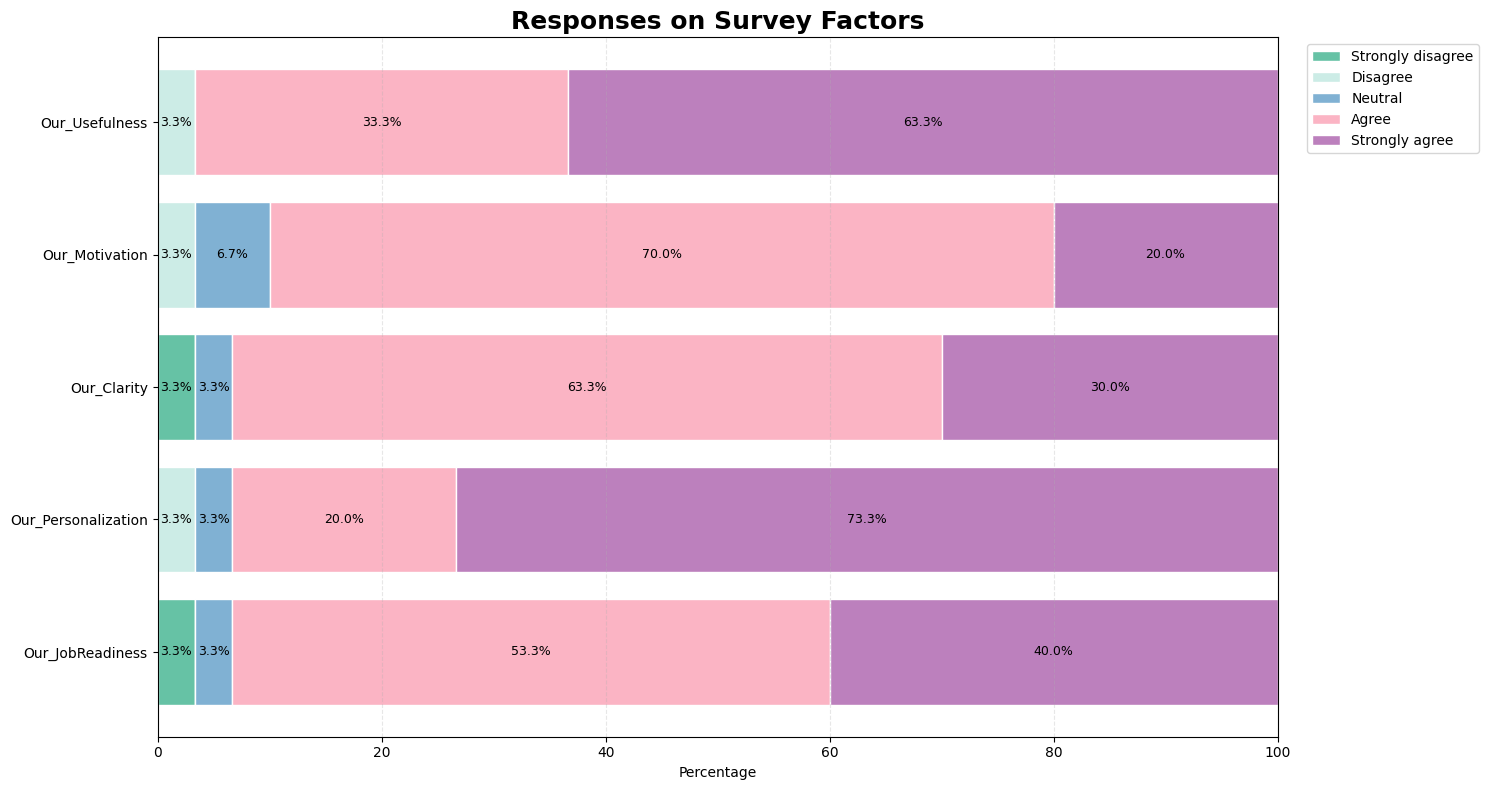

In [11]:
# =========================================
# CREATE PLOT
# =========================================

fig, ax = plt.subplots(figsize=(15,8))

left = np.zeros(len(percentage_df))

for i, category in enumerate(percentage_df.columns):

    values = percentage_df[category]

    bars = ax.barh(
        percentage_df.index,
        values,
        left=left,
        color=colors[i],
        edgecolor='white',
        label=category
    )

    # percentage labels
    for bar, value in zip(bars, values):

        if value > 3:

            ax.text(
                bar.get_x() + bar.get_width()/2,
                bar.get_y() + bar.get_height()/2,
                f'{value:.1f}%',
                ha='center',
                va='center',
                fontsize=9
            )

    left += values


# =========================================
# CUSTOMIZATION
# =========================================

ax.set_title(
    'Responses on Survey Factors',
    fontsize=18,
    fontweight='bold'
)

ax.set_xlabel('Percentage')

ax.set_xlim(0,100)

ax.legend(
    bbox_to_anchor=(1.02,1),
    loc='upper left'
)

ax.grid(axis='x', linestyle='--', alpha=0.3)

plt.tight_layout()

# =========================================
# SHOW
# =========================================

plt.show()

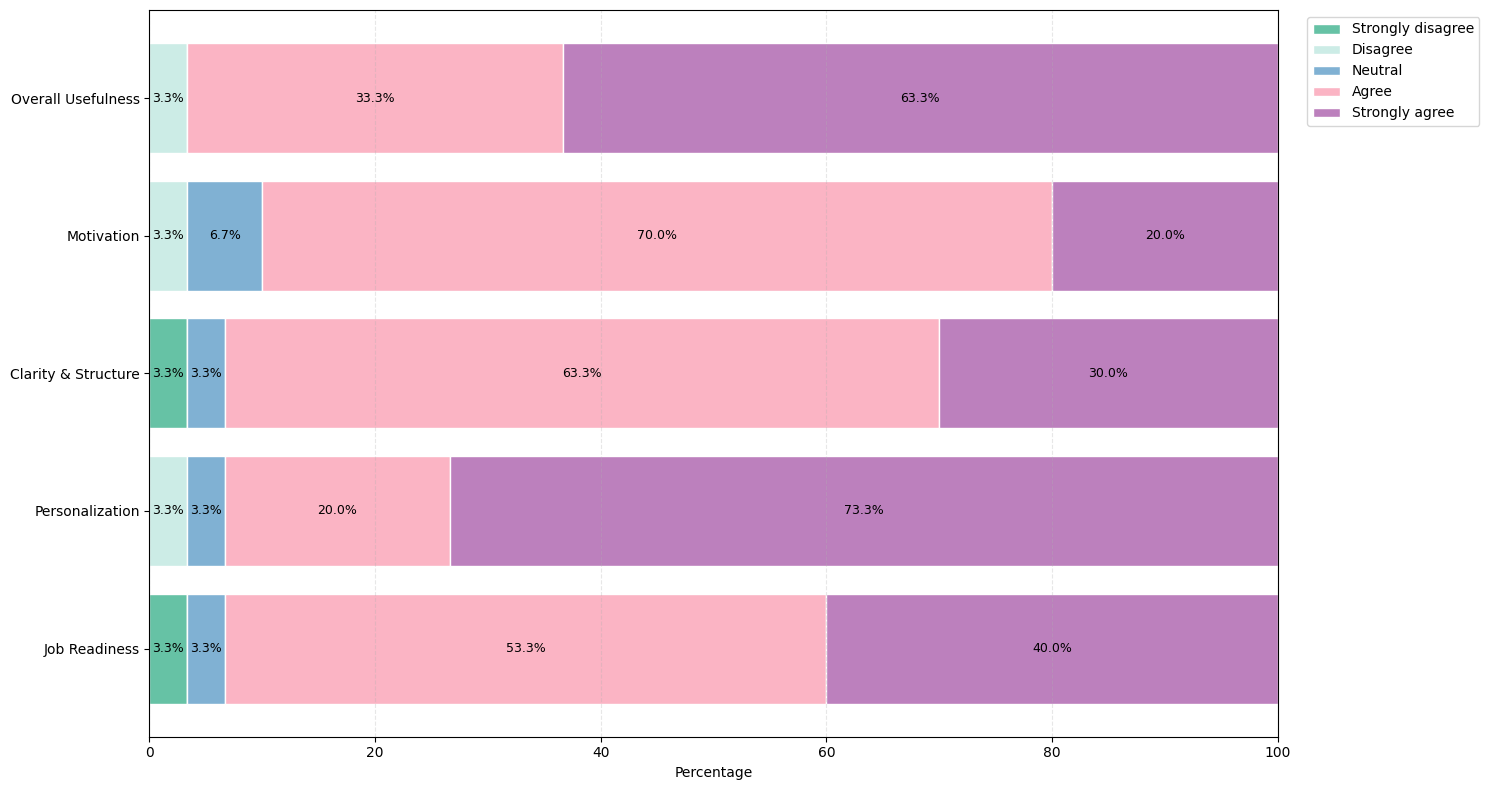

In [16]:
# 1. IMPORTS
# =========================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 2. LOAD DATA
# =========================================
# (Assuming you already uploaded the file to Colab)
df = pd.read_excel('/content/Student Evaluation Final.xlsx')

# 3. DEFINE COLUMNS & LIKERT SCALES
# =========================================
columns = [
    'Our_JobReadiness',
    'Our_Personalization',
    'Our_Clarity',
    'Our_Motivation',
    'Our_Usefulness'
]

likert_labels = [
    'Strongly disagree',
    'Disagree',
    'Neutral',
    'Agree',
    'Strongly agree'
]

# 4. PERCENTAGE CALCULATION
# =========================================
percentage_data = []

for col in columns:
    counts = (
        df[col]
        .value_counts(normalize=True)
        .sort_index()
        * 100
    )
    # Ensure all 1-5 scale values are represented even if 0 count
    counts = counts.reindex([1,2,3,4,5], fill_value=0)
    percentage_data.append(counts.values)

# Create the dataframe initially with the original column names
percentage_df = pd.DataFrame(
    percentage_data,
    columns=likert_labels,
    index=columns
)

# 5. APPLY CUSTOM LABELS (Your requested change!)
# =========================================
# Define exactly how you want each label to appear in the diagram
custom_labels = [
    'Job Readiness',
    'Personalization',
    'Clarity & Structure',
    'Motivation',
    'Overall Usefulness'
]

# Overwrite the index with the beautiful custom labels
percentage_df.index = custom_labels

# 6. COLORS SETUP
# =========================================
colors = [
    '#66c2a5',
    '#ccece6',
    '#80b1d3',
    '#fbb4c4',
    '#bc80bd'
]

# 7. CREATE PLOT
# =========================================
fig, ax = plt.subplots(figsize=(15,8))

left = np.zeros(len(percentage_df))

for i, category in enumerate(percentage_df.columns):
    values = percentage_df[category]

    bars = ax.barh(
        percentage_df.index,
        values,
        left=left,
        color=colors[i],
        edgecolor='white',
        label=category
    )

    # percentage labels inside bars
    for bar, value in zip(bars, values):
        if value > 3: # Only show text if the bar is wide enough
            ax.text(
                bar.get_x() + bar.get_width()/2,
                bar.get_y() + bar.get_height()/2,
                f'{value:.1f}%',
                ha='center',
                va='center',
                fontsize=9
            )

    left += values

# 8. CUSTOMIZATION & SHOW
# =========================================
ax.set_title('', fontsize=18, fontweight='bold')
ax.set_xlabel('Percentage')
ax.set_xlim(0, 100)

ax.legend(
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)

ax.grid(axis='x', linestyle='--', alpha=0.3)
plt.tight_layout()
# =========================================
# SAVE FOR JOURNAL PUBLICATION
# =========================================

# Save as a high-resolution PNG (300 DPI is standard for journals)
plt.savefig('Survey_Results_HighRes.png', dpi=300, bbox_inches='tight')

# Recommendation: Also save as a PDF (Vector format)
# Journals often prefer PDFs because they don't lose quality when zoomed in.
plt.savefig('Survey_Results_Vector.pdf', bbox_inches='tight')

# Keep this if you still want to see the plot in your notebook
plt.show()

In [15]:
# =========================================
# SAVE FOR JOURNAL PUBLICATION
# =========================================

# Save as a high-resolution PNG (300 DPI is standard for journals)
plt.savefig('Survey_Results_HighRes.png', dpi=300, bbox_inches='tight')

# Recommendation: Also save as a PDF (Vector format)
# Journals often prefer PDFs because they don't lose quality when zoomed in.
plt.savefig('Survey_Results_Vector.pdf', bbox_inches='tight')

# Keep this if you still want to see the plot in your notebook
plt.show()

<Figure size 640x480 with 0 Axes>

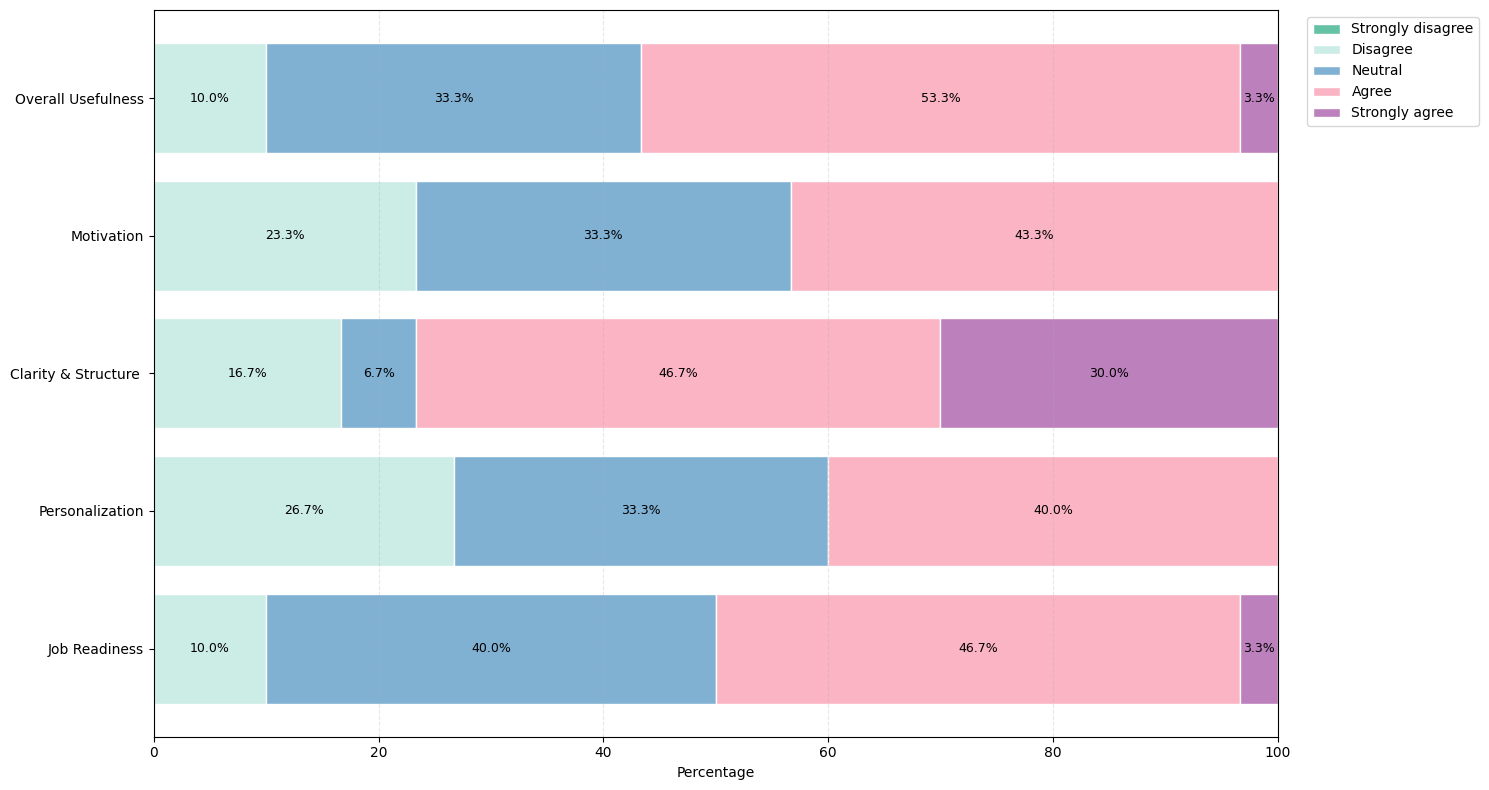

In [18]:
# 1. IMPORTS
# =========================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 2. LOAD DATA
# =========================================
# (Assuming you already uploaded the file to Colab)
df = pd.read_excel('/content/Student Evaluation Final.xlsx')

# 3. DEFINE COLUMNS & LIKERT SCALES
# =========================================
# Note: These are the BASE columns from your base1.ipynb
columns = [
    'Base_JobReadiness',
    'Base_Personalization',
    'Base_Clarity',
    'Base_Motivation',
    'Base_Usefulness'
]

likert_labels = [
    'Strongly disagree',
    'Disagree',
    'Neutral',
    'Agree',
    'Strongly agree'
]

# 4. PERCENTAGE CALCULATION
# =========================================
percentage_data = []

for col in columns:
    counts = (
        df[col]
        .value_counts(normalize=True)
        .sort_index()
        * 100
    )
    # Ensure all 1-5 scale values are represented even if 0 count
    counts = counts.reindex([1,2,3,4,5], fill_value=0)
    percentage_data.append(counts.values)

# Create the dataframe initially with the original column names
percentage_df = pd.DataFrame(
    percentage_data,
    columns=likert_labels,
    index=columns
)

# 5. APPLY CUSTOM LABELS (Clean format for diagram)
# =========================================
# Define exactly how you want each label to appear on the Y-Axis
custom_labels = [
    'Job Readiness',
    'Personalization',
    'Clarity & Structure ',
    'Motivation',
    'Overall Usefulness'
]

# Overwrite the index with the beautiful custom labels
percentage_df.index = custom_labels

# 6. COLORS SETUP
# =========================================
colors = [
    '#66c2a5',
    '#ccece6',
    '#80b1d3',
    '#fbb4c4',
    '#bc80bd'
]

# 7. CREATE PLOT
# =========================================
fig, ax = plt.subplots(figsize=(15,8))

left = np.zeros(len(percentage_df))

for i, category in enumerate(percentage_df.columns):
    values = percentage_df[category]

    bars = ax.barh(
        percentage_df.index,
        values,
        left=left,
        color=colors[i],
        edgecolor='white',
        label=category
    )

    # Percentage labels inside bars
    for bar, value in zip(bars, values):
        if value > 3: # Only show text if the bar is wide enough
            ax.text(
                bar.get_x() + bar.get_width()/2,
                bar.get_y() + bar.get_height()/2,
                f'{value:.1f}%',
                ha='center',
                va='center',
                fontsize=9
            )

    left += values

# 8. CUSTOMIZATION
# =========================================
ax.set_title('', fontsize=18, fontweight='bold')
ax.set_xlabel('Percentage')
ax.set_xlim(0, 100)

ax.legend(
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)

ax.grid(axis='x', linestyle='--', alpha=0.3)
plt.tight_layout()

# 9. SAVE FOR JOURNAL PUBLICATION & SHOW
# =========================================
# Saves as a high-res 300 DPI image (ideal for papers)
plt.savefig('Baseline_Survey_Results_HighRes.png', dpi=300, bbox_inches='tight')

# Saves as a vector graphic (does not lose quality upon zooming)
plt.savefig('Baseline_Survey_Results_Vector.pdf', bbox_inches='tight')

plt.show()

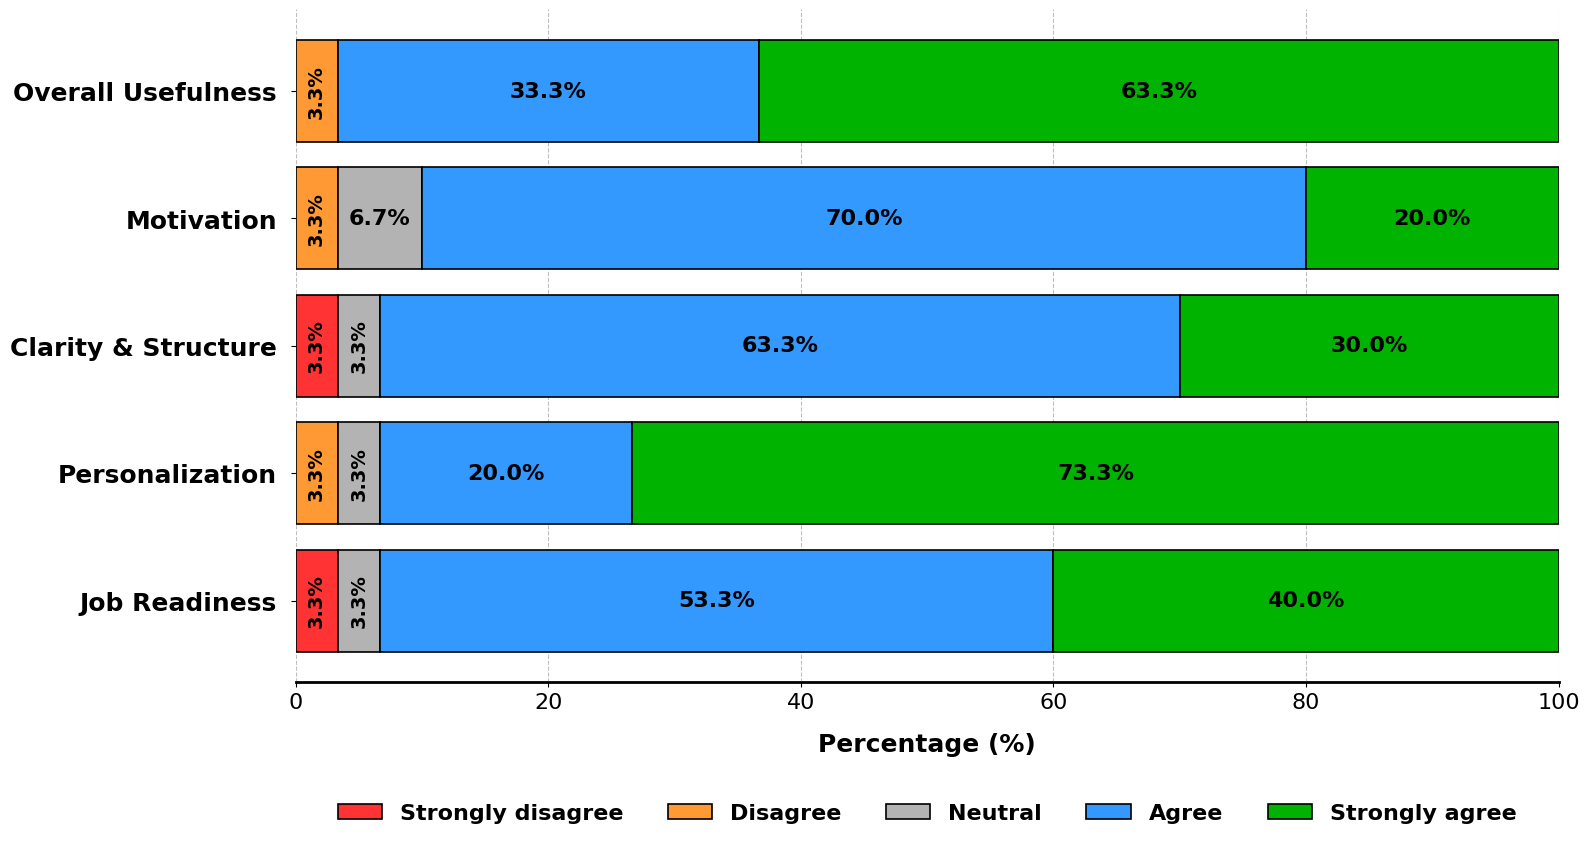

In [32]:
# 1. IMPORTS
# =========================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 2. LOAD DATA
# =========================================
# (Assuming you already uploaded the file to Colab)
df = pd.read_excel('/content/Student Evaluation Final.xlsx')

# 3. DEFINE COLUMNS & LIKERT SCALES
# =========================================
columns = [
    'Our_JobReadiness',
    'Our_Personalization',
    'Our_Clarity',
    'Our_Motivation',
    'Our_Usefulness'
]

likert_labels = [
    'Strongly disagree',
    'Disagree',
    'Neutral',
    'Agree',
    'Strongly agree'
]

# 4. PERCENTAGE CALCULATION
# =========================================
percentage_data = []

for col in columns:
    counts = (
        df[col]
        .value_counts(normalize=True)
        .sort_index()
        * 100
    )
    counts = counts.reindex([1,2,3,4,5], fill_value=0)
    percentage_data.append(counts.values)

percentage_df = pd.DataFrame(
    percentage_data,
    columns=likert_labels,
    index=columns
)

# 5. APPLY CUSTOM LABELS
# =========================================
custom_labels = [
    'Job Readiness',
    'Personalization',
    'Clarity & Structure',
    'Motivation',
    'Overall Usefulness'
]
percentage_df.index = custom_labels

# 6. COLORS SETUP (Vibrant, No White)
# =========================================
# Vibrant Red, Vibrant Orange, Medium Grey, Bright Blue, Vibrant Green
colors = ['#ff3333', '#ff9933', '#b3b3b3', '#3399ff', '#00b300']

# 7. CREATE PLOT (Wide Layout)
# =========================================
fig, ax = plt.subplots(figsize=(16, 8.5))

left = np.zeros(len(percentage_df))

for i, category in enumerate(percentage_df.columns):
    values = percentage_df[category]

    bars = ax.barh(
        percentage_df.index,
        values,
        left=left,
        color=colors[i],
        edgecolor='black',
        linewidth=1.2,
        label=category
    )

    # Percentage labels with Smart Rotation!
    for bar, value in zip(bars, values):
        if value > 0: # Only show non-zero values
            # Write vertically if the segment is small (less than 5%)
            if value < 5.0:
                ax.text(
                    bar.get_x() + bar.get_width() / 2,
                    bar.get_y() + bar.get_height() / 2,
                    f'{value:.1f}%',
                    ha='center',
                    va='center',
                    rotation=90,          # <-- ROTATES TEXT VERTICALLY
                    fontsize=14,          # Slightly smaller to fit bar height
                    fontweight='bold',
                    color='black'
                )
            # Write horizontally for normal/large segments
            else:
                ax.text(
                    bar.get_x() + bar.get_width() / 2,
                    bar.get_y() + bar.get_height() / 2,
                    f'{value:.1f}%',
                    ha='center',
                    va='center',
                    fontsize=16,
                    fontweight='bold',
                    color='black'
                )

    left += values

# 8. CUSTOMIZATION & SHOW
# =========================================
ax.set_xlabel('Percentage (%)', fontsize=18, fontweight='bold', labelpad=15, color='black')

# HUGE DIMENSION LABELS
ax.tick_params(axis='y', labelsize=18, labelcolor='black', pad=10)

# MAKE Y-AXIS DIMENSION LABELS BOLD
for label in ax.get_yticklabels():
    label.set_fontweight('bold')

ax.tick_params(axis='x', labelsize=16, labelcolor='black')
ax.set_xlim(0, 100)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_color('black')
ax.spines['bottom'].set_linewidth(2.0)

ax.grid(axis='x', linestyle='--', alpha=0.5, color='#808080')
ax.set_axisbelow(True)

# LEGEND
ax.legend(
    bbox_to_anchor=(0.5, -0.15),
    loc='upper center',
    ncol=5,
    frameon=False,
    prop={'weight': 'bold', 'size': 16},
    labelcolor='black'
)

plt.tight_layout()

# =========================================
# SAVE FOR JOURNAL PUBLICATION
# =========================================
plt.savefig('Pokpok.png', dpi=300, bbox_inches='tight')
plt.savefig('Our_Survey_Results_Final.pdf', bbox_inches='tight')

plt.show()

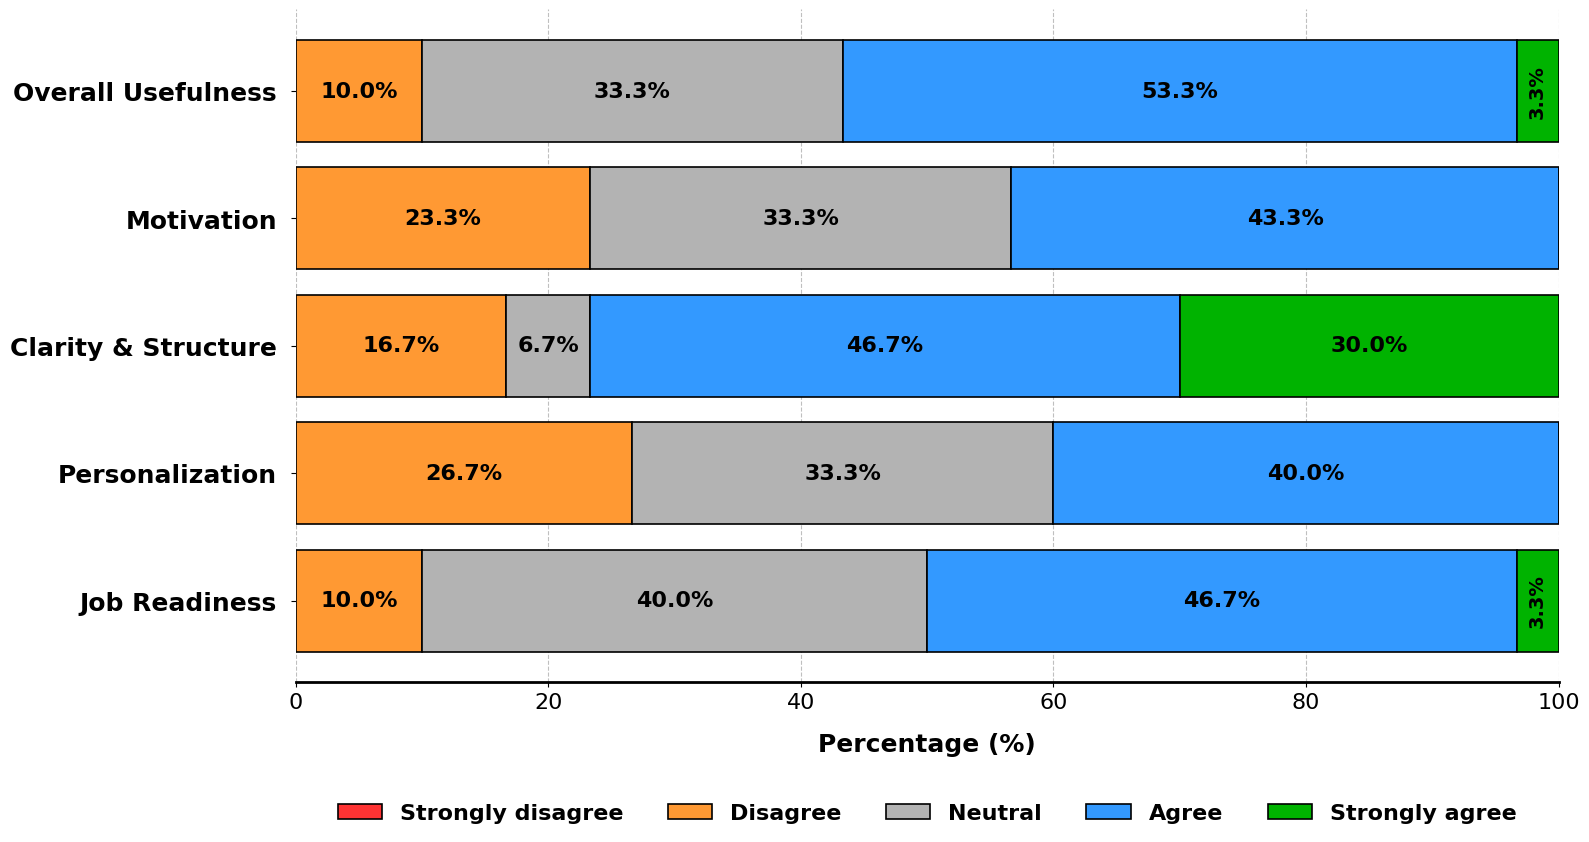

In [31]:
# 1. IMPORTS
# =========================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 2. LOAD DATA
# =========================================
# (Assuming you already uploaded the file to Colab)
df = pd.read_excel('/content/Student Evaluation Final.xlsx')

# 3. DEFINE COLUMNS & LIKERT SCALES
# =========================================
columns = [
    'Base_JobReadiness',
    'Base_Personalization',
    'Base_Clarity',
    'Base_Motivation',
    'Base_Usefulness'
]

likert_labels = [
    'Strongly disagree',
    'Disagree',
    'Neutral',
    'Agree',
    'Strongly agree'
]

# 4. PERCENTAGE CALCULATION
# =========================================
percentage_data = []

for col in columns:
    counts = (
        df[col]
        .value_counts(normalize=True)
        .sort_index()
        * 100
    )
    # Ensure all 1-5 scale values are represented even if 0 count
    counts = counts.reindex([1, 2, 3, 4, 5], fill_value=0)
    percentage_data.append(counts.values)

# Create the dataframe initially with the original column names
percentage_df = pd.DataFrame(
    percentage_data,
    columns=likert_labels,
    index=columns
)

# 5. APPLY CUSTOM LABELS
# =========================================
custom_labels = [
    'Job Readiness',
    'Personalization',
    'Clarity & Structure',
    'Motivation',
    'Overall Usefulness'
]

# Overwrite the index with the beautiful custom labels
percentage_df.index = custom_labels

# 6. COLORS SETUP (Vibrant, No White)
# =========================================
# Vibrant Red, Vibrant Orange, Medium Grey, Bright Blue, Vibrant Green
colors = ['#ff3333', '#ff9933', '#b3b3b3', '#3399ff', '#00b300']

# 7. CREATE PLOT (Wide Layout with Smart Text Rotation)
# =========================================
fig, ax = plt.subplots(figsize=(16, 8.5))

left = np.zeros(len(percentage_df))

for i, category in enumerate(percentage_df.columns):
    values = percentage_df[category]

    bars = ax.barh(
        percentage_df.index,
        values,
        left=left,
        color=colors[i],
        edgecolor='black',      # Pure black borders
        linewidth=1.2,          # Crisp separation lines
        label=category
    )

    # Percentage labels with Smart Rotation
    for bar, value in zip(bars, values):
        if value > 0: # Only show non-zero values
            # Write vertically if the segment is small (less than 5%)
            if value < 5.0:
                ax.text(
                    bar.get_x() + bar.get_width() / 2,
                    bar.get_y() + bar.get_height() / 2,
                    f'{value:.1f}%',
                    ha='center',
                    va='center',
                    rotation=90,          # <-- ROTATES TEXT VERTICALLY
                    fontsize=14,          # Slightly smaller to fit bar height
                    fontweight='bold',
                    color='black'
                )
            # Write horizontally for normal/large segments
            else:
                ax.text(
                    bar.get_x() + bar.get_width() / 2,
                    bar.get_y() + bar.get_height() / 2,
                    f'{value:.1f}%',
                    ha='center',
                    va='center',
                    fontsize=16,          # HUGE pure black text
                    fontweight='bold',
                    color='black'
                )

    left += values

# 8. CUSTOMIZATION & SHOW
# =========================================
ax.set_title('', fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Percentage (%)', fontsize=18, fontweight='bold', labelpad=15, color='black')

# HUGE DIMENSION LABELS
ax.tick_params(axis='y', labelsize=18, labelcolor='black', pad=10)

# MAKE Y-AXIS DIMENSION LABELS BOLD
for label in ax.get_yticklabels():
    label.set_fontweight('bold')

ax.tick_params(axis='x', labelsize=16, labelcolor='black')
ax.set_xlim(0, 100)

# Remove borders (spines) for a clean modern look
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_color('black')
ax.spines['bottom'].set_linewidth(2.0)

# Add subtle grid lines on the x-axis
ax.grid(axis='x', linestyle='--', alpha=0.5, color='#808080')
ax.set_axisbelow(True) # Put grid behind the bars

# Place Legend cleanly at the bottom (Huge and Bold)
ax.legend(
    bbox_to_anchor=(0.5, -0.15),
    loc='upper center',
    ncol=5, # 5 items side-by-side
    frameon=False,
    prop={'weight': 'bold', 'size': 16},
    labelcolor='black'
)

plt.tight_layout()

# 9. SAVE FOR JOURNAL PUBLICATION
# =========================================
# High resolution + perfectly cropped bounding box
plt.savefig('pokpok22.png', dpi=300, bbox_inches='tight')
plt.savefig('Baseline_Survey_Results_Final.pdf', bbox_inches='tight')

plt.show()